# Training Model
Training dan perbandingan Model A (CNN) dengan Model B (CNN + BiLSTM) memakai fitur dari Preprocessing_Data. Urutannya: ablation dengan cross-validation 5 fold untuk kedua model, lalu model yang dipilih di-train ulang, dites di data test, dan disimpan ke `outputs/model_final.pt`.

## 0. Setup

In [1]:
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay

plt.rcParams["figure.dpi"] = 110
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True  # hasil bisa diulang dengan seed yang sama
torch.backends.cudnn.benchmark = False
print("Device:", torch.cuda.get_device_name(0) if dev.type == "cuda" else "CPU")

Device: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
OUT = Path("outputs")
CLASSES = ["burping", "needs", "physical_pain", "scared"]
LR, BATCH = 1e-3, 32
MAX_EPOCH, PATIENCE = 60, 20    # maksimal 60 epoch; early stopping kalau F1-Macro validation tidak naik 20 epoch
DROPOUT = 0.3

## 1. Load data
Fitur asli dan hasil augmentation digabung jadi satu tensor dan langsung ditaruh di GPU (sekitar 300 MB dalam float16). Tiap batch tinggal diambil lewat nomor baris, jadi tidak perlu DataLoader. Baris 0 sampai jumlah klip - 1 adalah klip asli, sisanya salinan augmentation.

Sekitar sepertiga frame di kebanyakan klip adalah zero padding (klip < 6 detik). Panjang bagian yang berbunyi dihitung di sini (`n_all`), supaya nanti padding bisa diabaikan model.

In [3]:
d = pd.read_csv(OUT / "data_siap.csv")
X, X_aug = np.load(OUT / "X.npy"), np.load(OUT / "X_aug.npy")
N = len(d)

owner = np.empty(len(X_aug), dtype=int)  # baris X_aug ke-r adalah salinan dari klip owner[r]
owner[d.aug_row[d.aug_row >= 0]] = d.index[d.aug_row >= 0]
X_all = torch.from_numpy(np.concatenate([X, X_aug])).to(dev)        # float16, (klip asli + salinan, 104, 188)
y_all = torch.from_numpy(np.r_[d.y.values, d.y.values[owner]]).to(dev)

# panjang bagian yang berbunyi: frame zero padding punya nilai Mel minimum di semua 64 baris
mel = X_all[:, :64].float()
kosong = mel.amax(1) <= mel.amin((1, 2))[:, None] + 0.01            # (klip, 188), True = frame kosong
frame_akhir = torch.where(~kosong, torch.arange(188, device=dev), -1).amax(1) + 1
n_all = ((frame_akhir + 3) // 4).clamp(min=1)                       # jumlah langkah waktu setelah CNN (188 frame -> 47)
del mel, kosong
del X, X_aug

def rows(mask, aug=False):
    # nomor baris di X_all untuk klip yang dipilih mask; aug=True ikut ambil salinan augmentation-nya
    r = np.flatnonzero(mask)
    if aug:
        r = np.r_[r, N + d.aug_row.values[r]]
    return torch.as_tensor(r, device=dev)

assert (d.aug_row[d.split == "train"] >= 0).all()  # semua klip train punya salinan
print("X_all:", tuple(X_all.shape), "| klip asli:", N, "| salinan augmentation:", len(owner))
pd.crosstab(d.kelas, d.split)

X_all: (7878, 104, 188) | klip asli: 4240 | salinan augmentation: 3638


split,test,train
kelas,,
burping,24,174
needs,400,2399
physical_pain,80,479
scared,98,586


## 2. Arsitektur model
Kedua model memakai bagian CNN yang sama persis. Bedanya hanya BiLSTM di Model B, jadi kalau hasilnya berbeda, penyebabnya BiLSTM.

### 2.1 Blok CNN
Satu blok berisi Conv 3×3 → BatchNorm → ReLU → MaxPool. Conv mencari pola kecil di spektrogram, BatchNorm menjaga skala angka tetap stabil, ReLU membuang nilai negatif, dan MaxPool mengecilkan ukuran dengan mengambil nilai terbesar.

In [4]:
def conv_block(c_in, c_out, pool):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),  # padding=1 supaya ukuran tidak berubah sebelum pooling
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(pool),
    )

x = torch.zeros(1, 1, 104, 188)  # 1 klip, 1 channel, 104 baris fitur x 188 frame
print("masuk :", tuple(x.shape))
print("keluar:", tuple(conv_block(1, 32, (2, 2))(x).shape))  # 32 filter, tinggi dan lebar jadi setengah

masuk : (1, 1, 104, 188)
keluar: (1, 32, 52, 94)


### 2.2 Tiga blok CNN
Ukuran dicek di tiap blok. Blok ketiga hanya mengecilkan sumbu frekuensi (pool 2×1), supaya sumbu waktu tetap 47 langkah untuk dibaca BiLSTM.

In [5]:
cnn = nn.Sequential(conv_block(1, 32, (2, 2)), conv_block(32, 64, (2, 2)), conv_block(64, 128, (2, 1)))
for i, blok in enumerate(cnn, 1):
    x = blok(x)
    print(f"blok {i}:", tuple(x.shape))
x = x.mean(2).transpose(1, 2)  # rata-rata sumbu frekuensi, lalu jadikan urutan waktu
print("setelah rata-rata frekuensi:", tuple(x.shape), "-> 47 langkah waktu, tiap langkah 128 angka")

blok 1: (1, 32, 52, 94)
blok 2: (1, 64, 26, 47)
blok 3: (1, 128, 13, 47)
setelah rata-rata frekuensi: (1, 47, 128) -> 47 langkah waktu, tiap langkah 128 angka


### 2.3 Model A dan Model B
- **Model A**: hasil CNN langsung dirata-rata di sumbu waktu → Dropout → Linear → 4 logit.
- **Model B**: 47 langkah waktu dibaca BiLSTM dulu dari dua arah (64 angka maju + 64 mundur = 128), baru dirata-rata.

Di kedua model, rata-rata waktu hanya dihitung dari langkah yang berbunyi, dan BiLSTM hanya membaca sampai ujung suara. Kalau padding ikut dihitung, porsi padding memberi tahu panjang klip ke model, padahal panjang klip bukan ciri tangisan.

Logit adalah skor mentah tiap kelas. Saat prediksi, softmax mengubahnya jadi probabilitas.

In [6]:
class CryNet(nn.Module):
    def __init__(self, bilstm=False):
        super().__init__()
        self.cnn = nn.Sequential(conv_block(1, 32, (2, 2)), conv_block(32, 64, (2, 2)), conv_block(64, 128, (2, 1)))
        self.bilstm = nn.LSTM(128, 64, batch_first=True, bidirectional=True) if bilstm else None
        self.head = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(128, 4))

    def forward(self, x, n):               # x: (batch, 104, 188), n: jumlah langkah waktu yang berbunyi
        x = self.cnn(x.unsqueeze(1))       # (batch, 128, 13, 47)
        x = x.mean(2).transpose(1, 2)      # (batch, 47, 128)
        if self.bilstm is not None:
            # BiLSTM hanya membaca sampai ujung suara, zero padding di belakangnya dilewati
            x = nn.utils.rnn.pack_padded_sequence(x, n.cpu(), batch_first=True, enforce_sorted=False)
            x, _ = self.bilstm(x)
            x, _ = nn.utils.rnn.pad_packed_sequence(x, batch_first=True, total_length=47)  # (batch, 47, 128)
        ada = (torch.arange(x.shape[1], device=x.device) < n[:, None]).unsqueeze(2)       # True = berbunyi
        return self.head((x * ada).sum(1) / n[:, None])  # rata-rata waktu tanpa padding -> (batch, 4)

for nama, bl in [("A", False), ("B", True)]:
    print(f"Model {nama}:", tuple(CryNet(bl)(torch.zeros(2, 104, 188), torch.tensor([47, 30])).shape))  # 2 klip -> 4 logit per klip

Model A: (2, 4)
Model B: (2, 4)


### 2.4 Jumlah parameter
CNN 93.120 + Linear 516 = 93.636 untuk Model A. BiLSTM menambah 99.328, jadi Model B 192.964. Kedua model kecil, jadi training-nya cepat.

In [7]:
n_param = lambda m: sum(p.numel() for p in m.parameters())
pA, pB = n_param(CryNet(False)), n_param(CryNet(True))
assert (pA, pB) == (93_636, 192_964), (pA, pB)  # sesuai rancangan arsitektur
print(f"Model A: {pA:,} parameter | Model B: {pB:,} parameter")

Model A: 93,636 parameter | Model B: 192,964 parameter


## 3. Fungsi training
Satu fungsi dipakai untuk semua eksperimen:
- mean dan std tiap baris fitur (untuk normalisasi) serta class weight dihitung dari data train saja,
- Adam lr 0,001, batch 32, CrossEntropyLoss dengan class weight,
- learning rate turun pelan mengikuti kurva cosine, dari 0,001 di epoch pertama sampai hampir 0 di epoch terakhir (MAX_EPOCH),
- forward pass memakai mixed precision bf16 supaya training sekitar 1,7× lebih cepat di GPU,
- kalau ada data validation, dipakai early stopping: berhenti kalau F1-Macro validation tidak naik 20 epoch, lalu weight dari epoch terbaik dipakai lagi.

In [8]:
@torch.no_grad()
def predict(model, r, mean, std):
    model.eval()
    with torch.autocast(dev.type, dtype=torch.bfloat16):
        out = [model((X_all[r[i:i + 256]].float() - mean) / std, n_all[r[i:i + 256]]).argmax(1) for i in range(0, len(r), 256)]
    return torch.cat(out).cpu().numpy()

def fit(bilstm, seed, tr, va=None, epochs=MAX_EPOCH):
    torch.manual_seed(seed)
    xt = X_all[tr].float()
    mean, std = xt.mean((0, 2))[:, None], xt.std((0, 2))[:, None]  # (104, 1), dari data train saja
    del xt
    cnt = torch.bincount(y_all[tr], minlength=4).float()
    loss_fn = nn.CrossEntropyLoss(weight=len(tr) / (4 * cnt))     # class weight = N / (K x jumlah kelas)
    model = CryNet(bilstm).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCH)  # learning rate turun tiap epoch
    g = torch.Generator(device=dev).manual_seed(seed)             # urutan batch ikut seed
    y_va = None if va is None else y_all[va].cpu().numpy()
    best, best_ep, best_state, hist = -1.0, epochs, None, []

    for ep in range(1, epochs + 1):
        model.train()
        perm = tr[torch.randperm(len(tr), generator=g, device=dev)]  # acak urutan tiap epoch
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            with torch.autocast(dev.type, dtype=torch.bfloat16):  # mixed precision: training ~1,7x lebih cepat
                loss = loss_fn(model((X_all[b].float() - mean) / std, n_all[b]), y_all[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()
        if va is None:
            continue
        f1 = f1_score(y_va, predict(model, va, mean, std), average="macro")
        hist.append(f1)
        if f1 > best:
            best, best_ep = f1, ep
            best_state = {k: v.clone() for k, v in model.state_dict().items()}  # simpan weight terbaik
        elif ep - best_ep >= PATIENCE:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, mean, std, best, best_ep, hist

## 4. Ablation dengan cross-validation 5 fold
Model A dan B masing-masing di-train 5 kali (seed 42, dengan augmentation). Tiap kali, satu fold jadi data validation dan empat fold lainnya jadi data train, lalu hasil A dan B dibandingkan di fold yang sama.

Model B dipilih kalau rata-rata F1-Macro-nya lebih tinggi dari Model A **dan** B menang di minimal 4 dari 5 fold. Kalau tidak, Model A yang dipakai.

**Catatan revisi.** Rencana awal memakai fold 0 saja (3 seed, tanpa augmentation), dan rata-rata waktu masih ikut menghitung zero padding. Dengan cara itu Model A terpilih, dengan test F1-Macro 0,778. Setelah itu ketahuan bahwa porsi padding membocorkan panjang klip ke model (klip scared selalu di bawah 4 detik). Karena itu padding sekarang diabaikan di kedua model, dan ablation dibuat lebih kuat dengan 5 fold.

Fold validation juga dipakai untuk early stopping, jadi angka di bagian ini sedikit optimis. Angka yang jujur ada di data test (bagian 5).

In [9]:
cv = []
for nama, bl in [("A", False), ("B", True)]:
    for k in range(5):
        t = time.time()
        va = rows(d.fold == k)
        model, mean, std, f1, ep, _ = fit(bl, 42, rows((d.split == "train") & (d.fold != k), aug=True), va)
        per_kelas = f1_score(y_all[va].cpu().numpy(), predict(model, va, mean, std), average=None)  # F1 tiap kelas
        cv.append(dict(model=nama, fold=k, f1_macro=round(f1, 4), epoch_terbaik=ep,
                       **{c: round(float(v), 3) for c, v in zip(CLASSES, per_kelas)}, menit=round((time.time() - t) / 60, 1)))
        print(cv[-1])
cv = pd.DataFrame(cv)
cv.to_csv(OUT / "hasil_cv.csv", index=False)
cv.groupby("model").mean(numeric_only=True).drop(columns="fold").round(3)  # rata-rata 5 fold

{'model': 'A', 'fold': 0, 'f1_macro': 0.8224, 'epoch_terbaik': 41, 'burping': 0.581, 'needs': 0.935, 'physical_pain': 0.823, 'scared': 0.951, 'menit': 2.1}


{'model': 'A', 'fold': 1, 'f1_macro': 0.8527, 'epoch_terbaik': 41, 'burping': 0.86, 'needs': 0.923, 'physical_pain': 0.632, 'scared': 0.996, 'menit': 2.0}


{'model': 'A', 'fold': 2, 'f1_macro': 0.7704, 'epoch_terbaik': 55, 'burping': 0.554, 'needs': 0.911, 'physical_pain': 0.638, 'scared': 0.978, 'menit': 2.2}


{'model': 'A', 'fold': 3, 'f1_macro': 0.6645, 'epoch_terbaik': 11, 'burping': 0.329, 'needs': 0.866, 'physical_pain': 0.685, 'scared': 0.778, 'menit': 1.2}


{'model': 'A', 'fold': 4, 'f1_macro': 0.7449, 'epoch_terbaik': 58, 'burping': 0.577, 'needs': 0.899, 'physical_pain': 0.544, 'scared': 0.959, 'menit': 2.3}


...

{'model': 'B', 'fold': 1, 'f1_macro': 0.8601, 'epoch_terbaik': 46, 'burping': 0.857, 'needs': 0.929, 'physical_pain': 0.667, 'scared': 0.987, 'menit': 5.3}


{'model': 'B', 'fold': 2, 'f1_macro': 0.7973, 'epoch_terbaik': 56, 'burping': 0.556, 'needs': 0.929, 'physical_pain': 0.733, 'scared': 0.971, 'menit': 5.4}


{'model': 'B', 'fold': 3, 'f1_macro': 0.7883, 'epoch_terbaik': 45, 'burping': 0.51, 'needs': 0.926, 'physical_pain': 0.776, 'scared': 0.942, 'menit': 5.5}


{'model': 'B', 'fold': 4, 'f1_macro': 0.7826, 'epoch_terbaik': 44, 'burping': 0.525, 'needs': 0.921, 'physical_pain': 0.693, 'scared': 0.991, 'menit': 5.1}


,f1_macro,epoch_terbaik,burping,needs,physical_pain,scared,menit
model,,,,,,,
A,0.771,41.2,0.580,0.907,0.664,0.932,1.96
B,0.822,48.2,0.645,0.931,0.739,0.974,5.30


F1-Macro A: 0.7710 ± 0.0730 | B: 0.8222 ± 0.0459
B menang di 5 dari 5 fold | selisih rata-rata B - A: +0.0512
Model yang dipilih: B (CNN + BiLSTM)


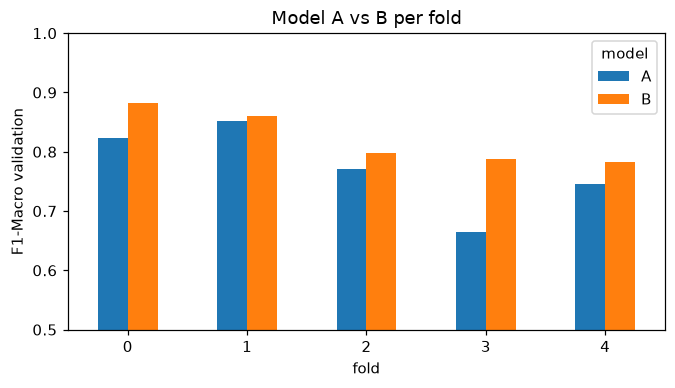

In [10]:
f1 = cv.pivot(index="fold", columns="model", values="f1_macro")
menang = int((f1.B > f1.A).sum())
USE_B = f1.B.mean() > f1.A.mean() and menang >= 4
print(f"F1-Macro A: {f1.A.mean():.4f} ± {f1.A.std():.4f} | B: {f1.B.mean():.4f} ± {f1.B.std():.4f}")
print(f"B menang di {menang} dari 5 fold | selisih rata-rata B - A: {f1.B.mean() - f1.A.mean():+.4f}")
print("Model yang dipilih:", "B (CNN + BiLSTM)" if USE_B else "A (CNN)")

ax = f1.plot.bar(figsize=(7, 3.5), rot=0, ylim=(0.5, 1), ylabel="F1-Macro validation", title="Model A vs B per fold")
ax.figure.savefig(OUT / "model_1_ablation.png", bbox_inches="tight"); plt.show()

## 5. Model final dan data test
Model di-train ulang di seluruh data train + augmentation, dengan jumlah epoch sama dengan rata-rata epoch terbaik dari 5 fold. Normalisasi dan class weight dihitung dari seluruh data train tersebut. Setelah itu model dites di data test.

Ini evaluasi kedua di data test. Evaluasi pertama (Model A, padding masih ikut dihitung) mendapat F1-Macro 0,778. Tidak ada pengaturan yang dipilih berdasarkan skor test.

Sebagai baseline, dihitung juga skor model yang selalu menebak kelas terbanyak (needs).

In [11]:
E = int(round(cv[cv.model == ("B" if USE_B else "A")].epoch_terbaik.mean()))  # rata-rata epoch terbaik model yang dipilih
model, mean, std, *_ = fit(USE_B, 42, rows(d.split == "train", aug=True), epochs=E)  # tanpa validation, langsung E epoch

te = rows(d.split == "test")
y_te, p_te = y_all[te].cpu().numpy(), predict(model, te, mean, std)
f1_te = f1_score(y_te, p_te, average="macro")
mayoritas = np.full_like(y_te, CLASSES.index("needs"))  # selalu menebak needs
print(f"Epoch: {E}")
print(f"Test F1-Macro: {f1_te:.4f} | accuracy: {accuracy_score(y_te, p_te):.4f}")
print(f"Baseline (selalu needs): F1-Macro {f1_score(y_te, mayoritas, average='macro'):.4f} | "
      f"accuracy {accuracy_score(y_te, mayoritas):.4f}")
print(classification_report(y_te, p_te, target_names=CLASSES, digits=3))

Epoch: 48
Test F1-Macro: 0.8010 | accuracy: 0.9169
Baseline (selalu needs): F1-Macro 0.1996 | accuracy 0.6645
               precision    recall  f1-score   support

      burping      0.435     0.417     0.426        24
        needs      0.947     0.940     0.944       400
physical_pain      0.816     0.887     0.850        80
       scared      1.000     0.969     0.984        98

     accuracy                          0.917       602
    macro avg      0.799     0.803     0.801       602
 weighted avg      0.918     0.917     0.917       602



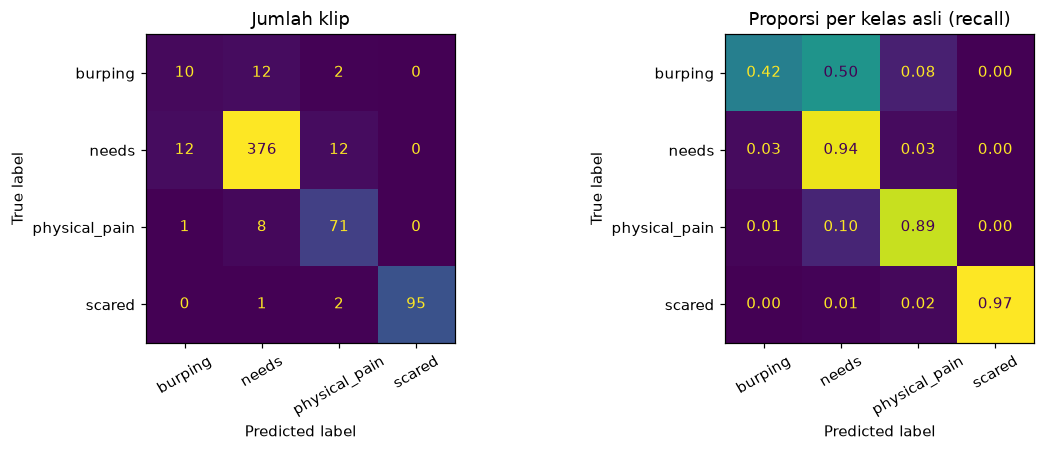

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y_te, p_te, display_labels=CLASSES, ax=ax[0], colorbar=False, xticks_rotation=30)
ConfusionMatrixDisplay.from_predictions(y_te, p_te, display_labels=CLASSES, ax=ax[1], colorbar=False, xticks_rotation=30,
                                        normalize="true", values_format=".2f")  # tiap baris dibagi jumlah klip kelas itu
ax[0].set_title("Jumlah klip"); ax[1].set_title("Proporsi per kelas asli (recall)")
fig.tight_layout(); fig.savefig(OUT / "model_2_confusion_matrix.png", bbox_inches="tight"); plt.show()

## 6. Simpan model
Model disimpan bersama mean/std normalisasi dan info training. Aplikasi nanti butuh mean/std yang sama dan cara menghitung `n` yang sama, supaya fitur dari audio pengguna diolah persis seperti saat training.

In [13]:
ckpt = dict(state_dict=model.state_dict(), bilstm=bool(USE_B), mean=mean.cpu(), std=std.cpu(), classes=CLASSES,
            dropout=DROPOUT, seed=42, epochs=E, f1_test=round(float(f1_te), 4), tanggal=str(date.today()))
torch.save(ckpt, OUT / "model_final.pt")

# cek: model yang dimuat ulang harus memberi prediksi yang sama
ck = torch.load(OUT / "model_final.pt")
m2 = CryNet(ck["bilstm"]).to(dev)  # DROPOUT tidak berpengaruh saat prediksi
m2.load_state_dict(ck["state_dict"])
assert (predict(m2, te, ck["mean"].to(dev), ck["std"].to(dev)) == p_te).all()
print("Tersimpan:", OUT / "model_final.pt", "| model", "B" if USE_B else "A", "| test F1-Macro", ck["f1_test"])

Tersimpan: outputs\model_final.pt | model B | test F1-Macro 0.801
